# Part 4 (extension): Basket options on many correlated stocks

**Aim of this part**

Part 3 showed that beyond a handful of dimensions Monte Carlo is the only general method left. Here we use it on a problem where grids are out of the question: a call on the average of up to 20 correlated stocks. A grid with even 10 points per stock would need $10^{20}$ points. The payoff we care about, the arithmetic average, has no closed form price, so we can no longer check the answer against an exact formula. Instead we use the geometric average, which does have a closed form, in two ways. First it checks that the correlated simulation is right, and then it acts as a control variate that makes the arithmetic price far more accurate for the same number of paths.

In [1]:
import sys
import time
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

from pricing import black_scholes as bs
from pricing import sde, basket
from pricing.plot_style import use_project_style, COLOURS, MARKERS, INK, GREY

use_project_style()

S0, K, r, sigma, T = 100.0, 100.0, 0.05, 0.2, 1.0
discount = np.exp(-r * T)
rng = np.random.default_rng(20)

**The model**

Each stock follows its own geometric Brownian motion,

$$S_i(T) = S_{0,i}\exp\left(\left(r - \tfrac{1}{2}\sigma_i^2\right)T + \sigma_i W_i(T)\right), \qquad i = 1, \dots, d,$$

where the Brownian motions are correlated, $\text{corr}(W_i(T), W_j(T)) = C_{ij}$. To keep the parameters simple, all stocks have $S_0 = 100$ and $\sigma = 0.2$, and every pair has the same correlation $\rho$, so $C = (1-\rho)I + \rho\,\mathbf{1}\mathbf{1}^T$. The eigenvalues of this matrix are $1 + (d-1)\rho$ (once) and $1 - \rho$ (the other $d-1$ times), so it is a valid, positive definite correlation matrix exactly when $-1/(d-1) < \rho < 1$.

To generate correlated normals we use the Cholesky factorisation $C = LL^T$, with $L$ lower triangular (Sauer Section 2.6). Cholesky is Gaussian elimination specialised to symmetric positive definite matrices, so it is another use of the Module 2 linear algebra. If $z$ is a vector of independent standard normals, then $Lz$ has covariance $L\,\mathbb{E}[zz^T]L^T = LL^T = C$, which is exactly what we need. The check below simulates $10^6$ draws for $d = 5$ and $\rho = 0.3$ and compares the sample correlations with $C$.

In [2]:
d, rho = 5, 0.3
corr = basket.equicorrelation_matrix(d, rho)
L = np.linalg.cholesky(corr)
print("Cholesky factor L for d = 5, rho = 0.3:")
print(np.round(L, 4))

z = rng.standard_normal((1_000_000, d))
W = z @ L.T  # each row is L z
sample_corr = np.corrcoef(W, rowvar=False)
print()
print(f"Largest difference between sample correlation and C: {np.max(np.abs(sample_corr - corr)):.4f}")

Cholesky factor L for d = 5, rho = 0.3:
[[1.     0.     0.     0.     0.    ]
 [0.3    0.9539 0.     0.     0.    ]
 [0.3    0.2201 0.9282 0.     0.    ]
 [0.3    0.2201 0.174  0.9117 0.    ]
 [0.3    0.2201 0.174  0.144  0.9003]]

Largest difference between sample correlation and C: 0.0012


With $10^6$ draws the sample correlations match $C$ to about three decimal places, which is the size of sampling error we expect, since the standard error of a correlation estimate is roughly $(1-\rho^2)/\sqrt{M} \approx 0.001$.

**Checking the simulation with the geometric basket**

The geometric average $G = \left(\prod_i S_i(T)\right)^{1/d}$ has $\ln G = \frac{1}{d}\sum_i \ln S_i(T)$, which is a linear combination of jointly normal variables and so is itself normal. Its mean and variance are

$$\mu = \frac{1}{d}\sum_{i=1}^d\left(\ln S_{0,i} + \left(r - \tfrac{1}{2}\sigma_i^2\right)T\right), \qquad v = \frac{T}{d^2}\sum_{i,j}\sigma_i\sigma_jC_{ij}.$$

For a lognormal variable, $\mathbb{E}[\max(G - K, 0)]$ follows from the same integral as the Black-Scholes formula, which gives

$$V_G = e^{-rT}\left(e^{\mu + v/2}N(d_1) - KN(d_2)\right), \qquad d_2 = \frac{\mu - \ln K}{\sqrt{v}}, \quad d_1 = d_2 + \sqrt{v}.$$

With equal volatilities and correlations, $v = \sigma^2T\left(1 + (d-1)\rho\right)/d$. As $d$ grows this tends to $\sigma^2T\rho$, so only the correlated part of the risk survives averaging. For $d = 1$ the formula reduces to Black-Scholes, which is one of the unit tests. The cell below compares the Monte Carlo geometric price with $V_G$ for several $d$ and $\rho$, using $M = 200000$ paths each.

 rho    d   closed form   Monte Carlo (std error)    z = (MC - exact) / std error


 0.0    2      7.6297       7.6730 (0.0227)          +1.90
 0.0    5      5.3429       5.3504 (0.0145)          +0.52


 0.0   10      4.2908       4.2817 (0.0106)          -0.86


 0.0   20      3.6194       3.6168 (0.0079)          -0.32
 0.3    2      8.5567       8.5852 (0.0261)          +1.09
 0.3    5      7.2294       7.2375 (0.0212)          +0.38
 0.3   10      6.7343       6.7271 (0.0195)          -0.37


 0.3   20      6.4730       6.4653 (0.0185)          -0.41
 0.7    2      9.6748       9.6317 (0.0301)          -1.43
 0.7    5      9.1854       9.1770 (0.0283)          -0.30


 0.7   10      9.0175       9.0912 (0.0278)          +2.65


 0.7   20      8.9326       8.9070 (0.0273)          -0.94


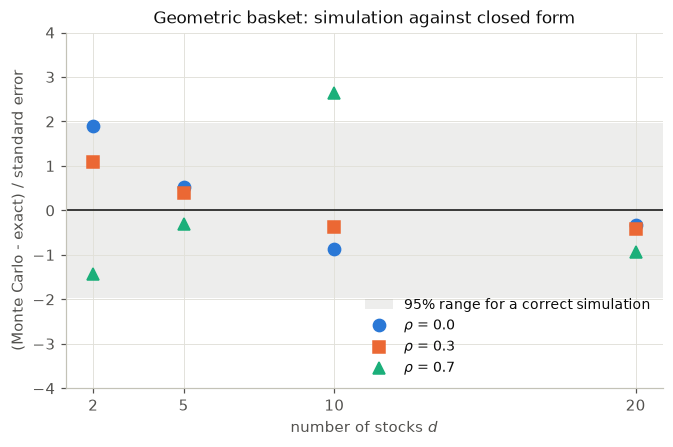

In [3]:
M = 200_000
dims = [2, 5, 10, 20]
rhos = [0.0, 0.3, 0.7]
z_scores = {}

print(" rho    d   closed form   Monte Carlo (std error)    z = (MC - exact) / std error")
for rho in rhos:
    z_scores[rho] = []
    for d in dims:
        corr = basket.equicorrelation_matrix(d, rho)
        S0s, sigmas = np.full(d, S0), np.full(d, sigma)
        S_T = basket.simulate_basket_terminal(S0s, r, sigmas, T, corr, M, rng)
        arithmetic, geometric = basket.basket_payoffs(S_T, K)
        exact = bs.geometric_basket_call_price(S0s, K, r, sigmas, T, corr)
        estimate, std_error = sde.mc_estimate(discount * geometric)
        z = (estimate - exact) / std_error
        z_scores[rho].append(z)
        print(f" {rho:.1f}   {d:2d}     {exact:7.4f}      {estimate:7.4f} ({std_error:.4f})          {z:+.2f}")

fig, ax = plt.subplots()
ax.axhspan(-1.96, 1.96, color=GREY, alpha=0.15, linewidth=0, label="95% range for a correct simulation")
for i, rho in enumerate(rhos):
    ax.plot(dims, z_scores[rho], marker=MARKERS[i], color=COLOURS[i], linestyle="none", markersize=8, label=rf"$\rho$ = {rho}")
ax.axhline(0, color=INK, linewidth=1)
ax.set_xticks(dims)
ax.set_ylim(-4, 4)
ax.set_xlabel("number of stocks $d$")
ax.set_ylabel("(Monte Carlo - exact) / standard error")
ax.set_title("Geometric basket: simulation against closed form")
ax.legend(loc="lower right")
fig.savefig("../figures/04_geometric_check.png")
plt.show()

Eleven of the twelve Monte Carlo prices are within two standard errors of the closed form. The odd one out is $\rho = 0.7$, $d = 10$, at $z = 2.65$. On its own that would happen by chance less than 1% of the time, but we made twelve comparisons, and the chance that at least one of twelve correct simulations lands this far out is about 9%. Rather than either ignoring it or panicking, we test it directly: if the simulation were biased for this case, fresh independent runs would keep landing on the same side.

In [4]:
d, rho = 10, 0.7
corr = basket.equicorrelation_matrix(d, rho)
S0s, sigmas = np.full(d, S0), np.full(d, sigma)
exact = bs.geometric_basket_call_price(S0s, K, r, sigmas, T, corr)
repeat_z = []
for run in range(10):
    S_T = basket.simulate_basket_terminal(S0s, r, sigmas, T, corr, 200_000, rng)
    arithmetic, geometric = basket.basket_payoffs(S_T, K)
    estimate, std_error = sde.mc_estimate(discount * geometric)
    repeat_z.append((estimate - exact) / std_error)
repeat_z = np.array(repeat_z)
print("z scores from 10 fresh runs:", np.round(repeat_z, 2))
print(f"Mean z = {np.mean(repeat_z):+.2f}; for an unbiased simulation this is normal with standard deviation 1/sqrt(10) = 0.32")

z scores from 10 fresh runs: [-0.5   0.28 -0.76 -2.03  2.45 -1.18 -0.5   0.85  0.07 -0.73]
Mean z = -0.20; for an unbiased simulation this is normal with standard deviation 1/sqrt(10) = 0.32


The ten fresh runs scatter on both sides of the closed form, with $z$ between $-2.0$ and $+2.5$ and a mean of $-0.20$, well inside the $\pm 0.63$ that an unbiased simulation would give 95% of the time. So the earlier $2.65$ was a fluctuation and not a bias. This kind of check is only possible because Monte Carlo comes with its own error estimate (Section 4.10): a suspicious result can be tested statistically and repeated, rather than just believed or explained away.

**The arithmetic basket and the control variate**

The product actually traded is the arithmetic basket call, with payoff $\max(A - K, 0)$ where $A = \frac{1}{d}\sum_i S_i(T)$. A sum of lognormals is not lognormal, so there is no closed form and plain Monte Carlo is the obvious tool. By the AM-GM inequality $A \ge G$ on every path, so the arithmetic call is always worth more than the geometric one. But the two payoffs are very strongly correlated, and that is exactly what a control variate needs.

Let $Y$ be the discounted arithmetic payoff and $X$ the discounted geometric payoff, whose mean $\mathbb{E}[X] = V_G$ we know exactly. For any constant $b$,

$$Y_{\text{cv}} = Y - b\left(X - \mathbb{E}[X]\right)$$

has the same mean as $Y$, and its variance $\text{Var}(Y) - 2b\,\text{Cov}(X,Y) + b^2\text{Var}(X)$ is smallest when $b = \text{Cov}(X,Y)/\text{Var}(X)$. The minimum is

$$\text{Var}(Y_{\text{cv}}) = \text{Var}(Y)\left(1 - \rho_{XY}^2\right),$$

where $\rho_{XY}$ is the correlation between the two payoffs. So the variance reduction factor is $1/(1-\rho_{XY}^2)$, and it becomes huge as $\rho_{XY} \to 1$. In other words, we let Monte Carlo estimate only the small difference between the arithmetic and geometric prices, and add back the geometric price exactly. This idea is due to Kemna and Vorst (1990), who used it for Asian options, where the average is over time instead of over stocks. We estimate $b$ from the same paths, which introduces a bias of order $1/M$, negligible next to the $1/\sqrt{M}$ standard error.

 rho    d   plain estimate (std error)   control variate (std error)    b      corr(X, Y)   variance reduction
 0.0    2      8.2757 (0.0236)           8.2979 (0.00284)        1.036    0.99278            69
 0.0    3      7.3663 (0.0197)           7.3715 (0.00280)        1.056    0.98989            50
 0.0    5      6.4422 (0.0158)           6.4666 (0.00254)        1.079    0.98705            39


 0.0   10      5.6579 (0.0119)           5.6487 (0.00217)        1.104    0.98335            30
 0.0   15      5.3249 (0.0101)           5.3331 (0.00195)        1.114    0.98131            27


 0.0   20      5.1859 (0.0091)           5.1726 (0.00179)        1.116    0.98015            25
 0.3    2      8.9851 (0.0266)           9.0153 (0.00198)        1.024    0.99725           182
 0.3    3      8.4559 (0.0244)           8.4577 (0.00195)        1.034    0.99680           157
 0.3    5      7.9788 (0.0223)           7.9691 (0.00177)        1.044    0.99686           159


 0.3   10      7.5671 (0.0205)           7.5707 (0.00153)        1.053    0.99724           181
 0.3   15      7.4508 (0.0200)           7.4309 (0.00141)        1.056    0.99749           200


 0.3   20      7.3403 (0.0197)           7.3567 (0.00135)        1.058    0.99763           211
 0.7    2      9.9007 (0.0304)           9.8683 (0.00085)        1.010    0.99961          1270
 0.7    3      9.6721 (0.0295)           9.6624 (0.00083)        1.013    0.99960          1247
 0.7    5      9.4616 (0.0287)           9.4937 (0.00076)        1.016    0.99965          1434


 0.7   10      9.3617 (0.0282)           9.3636 (0.00066)        1.018    0.99973          1845
 0.7   15      9.2857 (0.0280)           9.3195 (0.00061)        1.019    0.99976          2102


 0.7   20      9.3260 (0.0279)           9.2975 (0.00058)        1.019    0.99978          2288


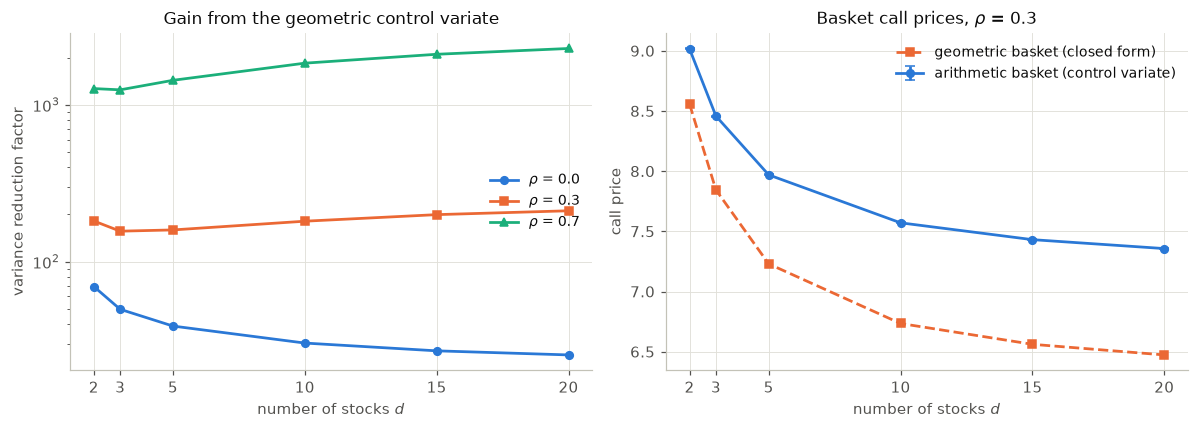

In [5]:
M = 200_000
dims = [2, 3, 5, 10, 15, 20]
results = {}

print(" rho    d   plain estimate (std error)   control variate (std error)    b      corr(X, Y)   variance reduction")
for rho in rhos:
    results[rho] = {"plain": [], "plain_se": [], "cv": [], "cv_se": [], "vrf": [], "geo": []}
    for d in dims:
        corr = basket.equicorrelation_matrix(d, rho)
        S0s, sigmas = np.full(d, S0), np.full(d, sigma)
        S_T = basket.simulate_basket_terminal(S0s, r, sigmas, T, corr, M, rng)
        arithmetic, geometric = basket.basket_payoffs(S_T, K)
        Y, X = discount * arithmetic, discount * geometric
        geometric_exact = bs.geometric_basket_call_price(S0s, K, r, sigmas, T, corr)

        plain, plain_se = sde.mc_estimate(Y)
        cv, cv_se, b = basket.control_variate_estimate(Y, X, geometric_exact)
        rho_xy = np.corrcoef(X, Y)[0, 1]
        vrf = (plain_se / cv_se) ** 2

        for key, value in [("plain", plain), ("plain_se", plain_se), ("cv", cv), ("cv_se", cv_se), ("vrf", vrf), ("geo", geometric_exact)]:
            results[rho][key].append(value)
        print(f" {rho:.1f}   {d:2d}     {plain:7.4f} ({plain_se:.4f})          {cv:7.4f} ({cv_se:.5f})        {b:.3f}    {rho_xy:.5f}       {vrf:7.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, rho in enumerate(rhos):
    axes[0].semilogy(dims, results[rho]["vrf"], marker=MARKERS[i], color=COLOURS[i], label=rf"$\rho$ = {rho}")
axes[0].set_xlabel("number of stocks $d$")
axes[0].set_ylabel("variance reduction factor")
axes[0].set_title("Gain from the geometric control variate")
axes[0].set_xticks(dims)
axes[0].legend(loc="center right")

rho = 0.3
axes[1].errorbar(dims, results[rho]["cv"], yerr=1.96 * np.array(results[rho]["cv_se"]), fmt="o-", color=COLOURS[0], capsize=3, label="arithmetic basket (control variate)")
axes[1].plot(dims, results[rho]["geo"], "s--", color=COLOURS[1], label="geometric basket (closed form)")
axes[1].set_xlabel("number of stocks $d$")
axes[1].set_ylabel("call price")
axes[1].set_title(r"Basket call prices, $\rho$ = 0.3")
axes[1].set_xticks(dims)
axes[1].legend()
fig.tight_layout()
fig.savefig("../figures/04_control_variate.png")
plt.show()

The control variate is extremely effective. The arithmetic and geometric payoffs have correlations between 0.980 and 0.9998, and the variance reduction factors range from about 25 to about 2300. For the 20 stock basket with $\rho = 0.3$ the control variate gives $7.3567 \pm 0.0026$ (a 95% interval), while plain Monte Carlo on the same 200000 paths gives $7.340 \pm 0.039$. To match the control variate, plain Monte Carlo would need about 211 times as many paths, around 42 million. In all 18 cases the two estimates agree to within about 1.2 plain standard errors, as they should, since both are unbiased estimates of the same price.

The trends make sense once we look at what separates $A$ from $G$. Writing $\ln S_i(T) = m + e_i$, where $m$ is the average of the logs, a Taylor expansion gives $A/G \approx 1 + \frac{1}{2}s^2$, where $s^2$ is the variance of the $e_i$ across the basket. So the two payoffs differ only through the spread of the stocks on each path. When the stocks are strongly correlated they move together, $s^2$ is small, and the control variate removes almost all of the noise. For independent stocks the reduction gets worse as $d$ grows. The average itself becomes less volatile (its variance is $\sigma^2T/d$), but the spread between the stocks does not shrink, so more and more of the remaining variance sits in the part the control variate cannot see. For correlated stocks the common part of the risk, which both averages share, dominates instead, and the reduction improves with $d$. The right panel shows the arithmetic price always above the geometric one, as AM-GM requires. The gap grows with $d$ because the cross sectional spread has more stocks to act on.

**Cost as the number of stocks grows**

The work per path has three parts. The Cholesky factorisation costs $O(d^3)$ but is done once. Multiplying each normal vector by $L$ costs $O(d^2)$ per path. Exponentials, logs and averages cost $O(d)$ per path. So the cost grows polynomially in $d$, compared with the exponential $n^d$ of a grid. The cell below times the full pricing (simulation, both payoffs and the control variate) with $10^5$ paths for $d$ up to 100.

d =   1   time for 100000 paths = 0.009 s
d =   2   time for 100000 paths = 0.022 s


d =   5   time for 100000 paths = 0.042 s
d =  10   time for 100000 paths = 0.065 s


d =  20   time for 100000 paths = 0.106 s


d =  50   time for 100000 paths = 0.235 s


d = 100   time for 100000 paths = 0.479 s
Fitted growth of time with d (for d >= 5): d^0.81


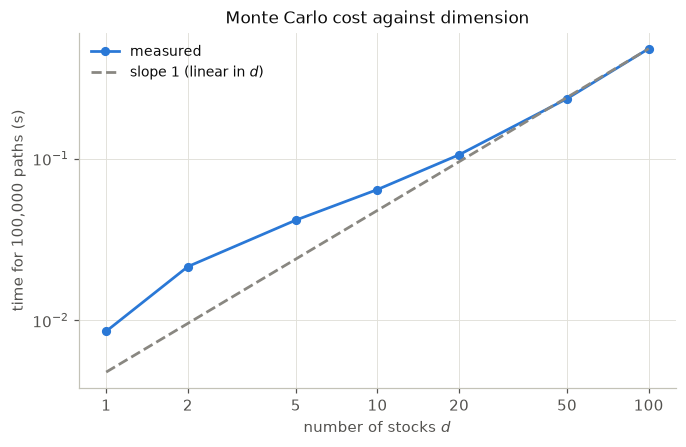

In [6]:
M = 100_000
dims_timing = [1, 2, 5, 10, 20, 50, 100]
times = []
for d in dims_timing:
    corr = basket.equicorrelation_matrix(d, 0.3)
    S0s, sigmas = np.full(d, S0), np.full(d, sigma)
    best = np.inf
    for repeat in range(3):
        start = time.perf_counter()
        S_T = basket.simulate_basket_terminal(S0s, r, sigmas, T, corr, M, rng)
        arithmetic, geometric = basket.basket_payoffs(S_T, K)
        geometric_exact = bs.geometric_basket_call_price(S0s, K, r, sigmas, T, corr)
        basket.control_variate_estimate(discount * arithmetic, discount * geometric, geometric_exact)
        best = min(best, time.perf_counter() - start)
    times.append(best)
    print(f"d = {d:3d}   time for {M} paths = {best:.3f} s")

times = np.array(times)
slope = np.polyfit(np.log(dims_timing[2:]), np.log(times[2:]), 1)[0]
print(f"Fitted growth of time with d (for d >= 5): d^{slope:.2f}")

fig, ax = plt.subplots()
ax.loglog(dims_timing, times, "o-", color=COLOURS[0], label="measured")
ref_d = np.array(dims_timing, dtype=float)
ax.loglog(ref_d, times[-1] * ref_d / ref_d[-1], "--", color=GREY, label="slope 1 (linear in $d$)")
ax.set_xlabel("number of stocks $d$")
ax.set_ylabel(f"time for {M:,} paths (s)")
ax.set_title("Monte Carlo cost against dimension")
ax.minorticks_off()
ax.set_xticks(dims_timing, labels=[str(d) for d in dims_timing])
ax.legend()
fig.savefig("../figures/04_cost_vs_dimension.png")
plt.show()

The time grows roughly linearly with $d$ (a fitted exponent of about 0.9 for $d \ge 5$), so a 100 stock basket with $10^5$ paths and the control variate takes about half a second. In theory the $O(d^2)$ matrix product should eventually dominate, but at these sizes it is handled by optimised linear algebra routines and costs less than the $O(d)$ exponentials and logarithms. Compare a tensor product grid with only 10 points per stock: for $d = 20$ it would need $10^{20}$ points, roughly 800 exabytes just to store one array of them.

**Discussion**

This extension puts the conclusion of Part 3 into practice. With 20 correlated stocks a grid is impossible, and plain Monte Carlo works but is noisy, with a standard error of about 0.02 from 200000 paths. The geometric basket's closed form did two jobs. First it was an exact benchmark that validated the correlated simulation, and for a product with no closed form a benchmark like this is the main way to test a pricer. Then it was a control variate that reduced the variance by factors of 25 to over 2000. Meanwhile the cost per path grew only about linearly with $d$.

The main limitations are in the setup. All stocks share the same volatility and pairwise correlation. With very different volatilities the arithmetic and geometric averages drift further apart, so the control variate is less effective, although it stays unbiased. We only treated European payoffs, which depend on the $S_i(T)$ alone, so no time stepping was needed. A path dependent basket would bring back the Euler-Maruyama bias of Part 2. Finally, other variance reduction methods, such as antithetic variates or quasi-random (low discrepancy) points, could be combined with the control variate for further gains.